# Payment Pulse: Merchant Payment Disruption Early Warning

**Theme:** Real-Time AI for Critical Decisions — detect and respond to payment-service disruption as transaction events arrive.

This project uses the card transaction CSV to monitor changes in transaction volume and recorded processing errors by city and hour. It forecasts expected activity with XGBoost and identifies unusual multivariate patterns with scikit-learn Isolation Forest. A flagged period means ‘investigate service health’; it is not proof of an outage or fraud. The `Is Fraud?` field is deliberately ignored, so this is a different problem from the mandatory fraud-detection lab. A human operator decides what to do; the notebook never blocks or reroutes payments.

## Visual guide: how Payment Pulse works

Read the illustration from left to right: transaction events are summarized into area-level activity, models compare the observed pattern with expected behavior, and a human operator reviews any warning. Orange markers indicate example error signals; the artwork is explanatory, not real measured output.

## Payment Pulse: input-to-output flow

This diagram shows how transaction CSV rows become short time-window signals, how the two models analyze them, and how the resulting alert supports a human decision. The output is a review cue, not an automatic action.

## 1. Load a bounded, representative sample

The CSV is large and may be sorted by user or card. Instead of taking the first 150,000 rows, this cell makes a one-pass uniform reservoir sample across the whole file. It reads only the fields needed for area-level monitoring and drops the fraud label. The full-file scan costs I/O time but keeps memory bounded.

The project includes `payment_pulse_synthetic_29mb.csv` (about 29.0 MB), which this notebook uses by default to fit under a 30 MB upload limit. It is a deterministic, uniformly sampled copy of the original 345,000-row CSV; the original file is unchanged. Upload the smaller CSV beside the notebook or to `~/shared/`; this cell checks both locations. To use another compatible CSV, set `PAYMENT_PULSE_CSV` before running the data-loading cell. You can also set `PAYMENT_PULSE_CSV` to an exact path before running the cell. The output prints the selected path and file size. Matching column names alone does not prove two CSV files contain the same data; compare SHA-256 hashes if exact identity matters. The saved outputs in this notebook document the earlier L1CC run and will update after you rerun all cells with your uploaded CSV.

![Illustration: CSV loading and representative sampling](assets/step1-data-loading.png)


In [ ]:
from pathlib import Path
import json, math, os, time, warnings
import numpy as np
import pandas as pd

requested_csv = os.environ.get('PAYMENT_PULSE_CSV', '').strip()
if requested_csv:
    CSV_PATH = Path(requested_csv).expanduser()
    if not CSV_PATH.is_file():
        raise FileNotFoundError(f'PAYMENT_PULSE_CSV does not exist: {CSV_PATH}')
else:
    candidate_paths = [
        Path('payment_pulse_synthetic_29mb.csv'),
        Path.home() / 'shared' / 'payment_pulse_synthetic_29mb.csv',
        Path('payment_pulse_synthetic.csv'),
        Path.home() / 'shared' / 'payment_pulse_synthetic.csv',
        Path.home() / 'shared' / 'card_transaction.v1.csv',
        Path('card_transaction.v1.csv'),
        Path.home() / 'shared' / 'transactions_history.csv',
        Path('transactions_history.csv'),
        Path.home() / 'transactions_history.csv',
    ]
    CSV_PATH = next((p for p in candidate_paths if p.is_file()), None)
if CSV_PATH is None:
    raise FileNotFoundError('Place payment_pulse_synthetic_29mb.csv beside the notebook or in ~/shared/, upload another compatible CSV, or set PAYMENT_PULSE_CSV to its exact path.')
CSV_PATH = CSV_PATH.resolve()

SAMPLE_ROWS = 150_000
CHUNK_ROWS = 100_000
SEED = 42
USECOLS = ['Card', 'Year', 'Month', 'Day', 'Time', 'Amount', 'Merchant City', 'Merchant State', 'Errors?']
DTYPES = {'Time': 'string', 'Merchant City': 'string', 'Merchant State': 'string', 'Errors?': 'string'}
header = pd.read_csv(CSV_PATH, nrows=0).columns.tolist()
missing = set(USECOLS) - set(header)
if missing:
    raise ValueError(f'Missing required CSV fields: {sorted(missing)}')
source_has_terminal_id = any('terminal' in column.lower() for column in header)

# Keep rows with the smallest random keys seen so far: this is a uniform reservoir sample.
def uniform_csv_sample(path, sample_size, chunksize=CHUNK_ROWS, seed=SEED):
    if sample_size < 1:
        raise ValueError('SAMPLE_ROWS must be positive.')
    rng = np.random.default_rng(seed)
    kept = pd.DataFrame()
    kept_keys = np.empty(0, dtype=np.float64)
    rows_scanned = 0
    reader = pd.read_csv(path, usecols=USECOLS, dtype=DTYPES, chunksize=chunksize, low_memory=False)
    for chunk in reader:
        keys = rng.random(len(chunk))
        if len(kept):
            candidates = pd.concat([kept, chunk], ignore_index=True)
            candidate_keys = np.concatenate([kept_keys, keys])
        else:
            candidates, candidate_keys = chunk, keys
        if len(candidates) > sample_size:
            chosen = np.argpartition(candidate_keys, sample_size - 1)[:sample_size]
            kept = candidates.iloc[chosen].reset_index(drop=True)
            kept_keys = candidate_keys[chosen]
        else:
            kept, kept_keys = candidates.reset_index(drop=True), candidate_keys
        rows_scanned += len(chunk)
    return kept, rows_scanned

raw, source_rows_scanned = uniform_csv_sample(CSV_PATH, SAMPLE_ROWS)
print(f'Dataset selected: {CSV_PATH}')
print(f'File size: {CSV_PATH.stat().st_size:,} bytes')
print(f'Rows scanned across full file: {source_rows_scanned:,}')
print(f'Uniform sample retained: {len(raw):,} rows; random seed={SEED}')
print(f'Terminal identifier available: {source_has_terminal_id}')
print('Fraud label used in analysis: False')
display(raw.drop(columns=['Card']).head(5))


## 2. Dataset statistics and data quality

These describe the random sample and its source coverage. They are not outage labels or model-performance scores. User, card, and fraud-label fields are excluded from displayed analysis.


In [ ]:
from pathlib import Path
from IPython.display import Image, Markdown, display
display(Markdown("**Illustration: data profiling; the statistics below are computed from the selected CSV**"))
display(Image(filename=str(Path('assets/step2-data-profile.png')), width=1050))
print('Sample rows / selected columns:', raw.shape)
print('Rows scanned across source:', f'{source_rows_scanned:,}')
print('Unique cities:', raw['Merchant City'].nunique(dropna=True))
print('Unique states:', raw['Merchant State'].nunique(dropna=True))
print('Recorded error rows:', int(raw['Errors?'].fillna('').str.strip().ne('').sum()))
print('Missing values (top 12):')
display(raw.isna().sum().sort_values(ascending=False).head(12).to_frame('missing_rows'))
display(raw[['Merchant City', 'Merchant State', 'Errors?']].describe(include='all'))


## 3. Prepare area-level operating signals and check sparsity

Start at city/hour, then broaden to state/hour, state/day, or state/week if more than half of the resulting windows contain fewer than three events. This protects the model from pretending sparse single-event windows are stable. The selected grain is reported. Coarser windows reduce time resolution; the source does not support terminal-level or genuine real-time outage detection.


In [ ]:
from pathlib import Path
from IPython.display import Image, Markdown, display
display(Markdown("**Illustration: transaction windows and decision-support flow**"))
display(Image(filename=str(Path('assets/step3-aggregation-flow.png')), width=1050))
def make_area_windows(frame, grain='city_hour'):
    d = frame.copy()
    time_text = d['Time'].astype('string').str.slice(0, 5)
    date_text = (d['Year'].astype('Int64').astype('string') + '-' + d['Month'].astype('Int64').astype('string').str.zfill(2) + '-' + d['Day'].astype('Int64').astype('string').str.zfill(2))
    d['event_time'] = pd.to_datetime(date_text + ' ' + time_text, errors='coerce')
    d = d.dropna(subset=['event_time'])
    if grain.endswith('_day'):
        d['window_start'] = d['event_time'].dt.floor('D')
    elif grain.endswith('_week'):
        d['window_start'] = d['event_time'].dt.to_period('W').dt.start_time
    else:
        d['window_start'] = d['event_time'].dt.floor('h')
    d['city'] = d['Merchant City'].fillna('Unknown').astype(str).str.strip()
    d['state'] = d['Merchant State'].fillna('Unknown').astype(str).str.strip()
    d['area'] = d['city'] + ' | ' + d['state']
    if grain.startswith('state_'):
        d['city'] = 'State roll-up'
        d['area'] = d['state']
    d['has_error'] = d['Errors?'].fillna('').astype(str).str.strip().ne('').astype(int)
    d['amount_value'] = pd.to_numeric(d['Amount'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
    windows = (d.groupby(['area', 'city', 'state', 'window_start'], as_index=False, observed=True)
        .agg(event_count=('Card', 'size'), error_count=('has_error', 'sum'), unique_cards=('Card', 'nunique'), mean_amount=('amount_value', 'mean'), amount_std=('amount_value', 'std')))
    windows['error_rate'] = windows['error_count'] / windows['event_count'].clip(lower=1)
    windows['mean_amount'] = windows['mean_amount'].fillna(0)
    windows['amount_std'] = windows['amount_std'].fillna(0)
    windows['hour'] = windows['window_start'].dt.hour
    windows['day_of_week'] = windows['window_start'].dt.dayofweek
    return windows.sort_values(['area', 'window_start']).reset_index(drop=True)

city_hour_windows = make_area_windows(raw, 'city_hour')
city_hour_sparse_share = float((city_hour_windows['event_count'] < 3).mean())
windows = city_hour_windows
AGGREGATION_GRAIN = 'city/hour'
state_hour_sparse_share = float('nan')
state_day_sparse_share = float('nan')
if city_hour_sparse_share > 0.50:
    windows = make_area_windows(raw, 'state_hour')
    AGGREGATION_GRAIN = 'state/hour'
state_hour_sparse_share = float((windows['event_count'] < 3).mean())
if state_hour_sparse_share > 0.50:
    windows = make_area_windows(raw, 'state_day')
    AGGREGATION_GRAIN = 'state/day'
state_day_sparse_share = float((windows['event_count'] < 3).mean())
if AGGREGATION_GRAIN == 'state/day' and state_day_sparse_share > 0.50:
    windows = make_area_windows(raw, 'state_week')
    AGGREGATION_GRAIN = 'state/week'
print(f'Aggregation grain selected: {AGGREGATION_GRAIN}')
print(f'City/hour windows below 3 events: {city_hour_sparse_share:.1%}')
print('State/hour windows below 3 events:', f'{state_hour_sparse_share:.1%}')
if np.isfinite(state_day_sparse_share):
    print('State/day windows below 3 events:', f'{state_day_sparse_share:.1%}')
print(f'Final windows: {len(windows):,} across {windows.area.nunique():,} areas.')
print('Final event_count distribution:')
display(windows['event_count'].describe(percentiles=[.1, .25, .5, .75, .9]).to_frame())
print('Final windows with fewer than 3 events:', f'{(windows.event_count < 3).mean():.1%}')
display(windows.head(8))


## 4. Explore traffic and error patterns (graphs)

These plots show the data the models will analyze. A spike in recorded errors or a sudden activity drop can signal a service issue, but this historical sample has no verified outage labels.

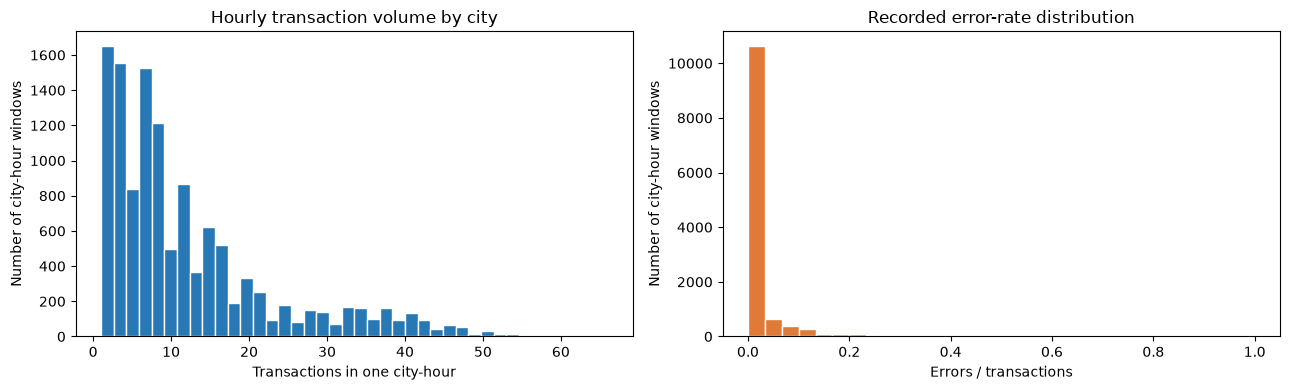

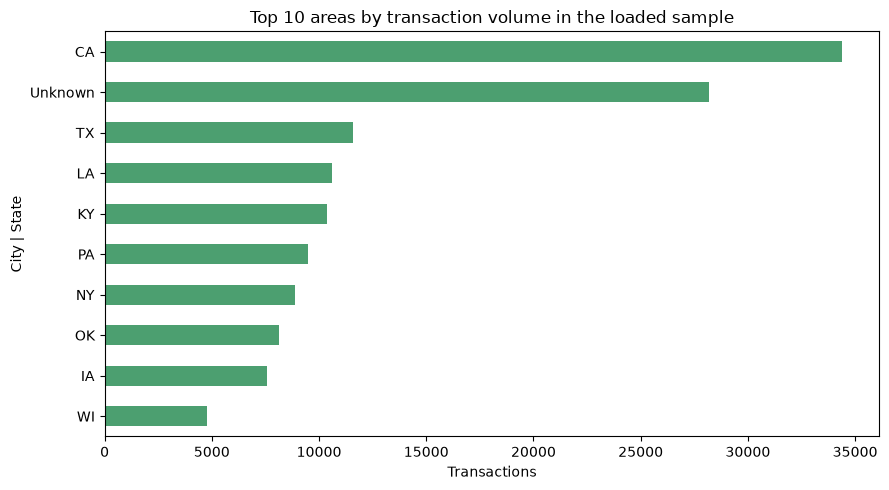

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(windows['event_count'], bins=40, color='#2878b5', edgecolor='white')
axes[0].set(title='Hourly transaction volume by city', xlabel='Transactions in one city-hour', ylabel='Number of city-hour windows')
axes[1].hist(windows['error_rate'], bins=30, color='#e07a37', edgecolor='white')
axes[1].set(title='Recorded error-rate distribution', xlabel='Errors / transactions', ylabel='Number of city-hour windows')
plt.tight_layout(); plt.show()

top_areas = windows.groupby('area')['event_count'].sum().sort_values(ascending=False).head(10).sort_values()
plt.figure(figsize=(9,5)); top_areas.plot.barh(color='#4c9f70')
plt.title('Top 10 areas by transaction volume in the loaded sample'); plt.xlabel('Transactions'); plt.ylabel('City | State'); plt.tight_layout(); plt.show()

## 5. Project flow diagram

This image summarizes the decision-support workflow: events become hourly aggregates, two models produce independent signals, and a human operator reviews alerts.

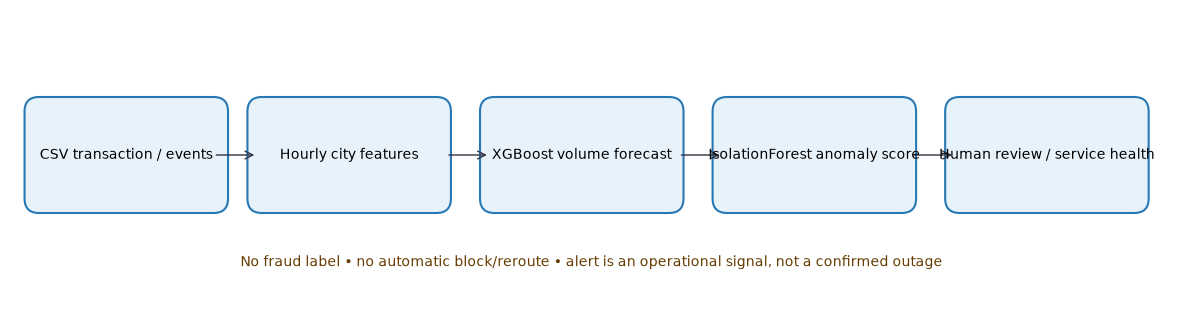

In [7]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 3.2)); ax.set_xlim(0,12); ax.set_ylim(0,3); ax.axis('off')
boxes = [(0.3,'CSV transaction / events'),(2.6,'Hourly city features'),(5.0,'XGBoost volume forecast'),(7.4,'IsolationForest anomaly score'),(9.8,'Human review / service health')]
for x,label in boxes:
    box=FancyBboxPatch((x,1.05),1.8,0.9,boxstyle='round,pad=0.15',fc='#e8f2fa',ec='#2878b5',lw=1.5); ax.add_patch(box); ax.text(x+0.9,1.5,label,ha='center',va='center',fontsize=10)
for x in [2.1,4.5,6.9,9.3]: ax.add_patch(FancyArrowPatch((x,1.5),(x+0.45,1.5),arrowstyle='->',mutation_scale=14,color='#334'))
ax.text(6,0.35,'No fraud label • no automatic block/reroute • alert is an operational signal, not a confirmed outage',ha='center',fontsize=10,color='#663c00')
plt.tight_layout(); plt.show()

## 6. Train two models on the sampled data

**XGBoost** forecasts the next area/window volume from prior windows. **Isolation Forest** flags multivariate deviations in volume, error rate, card count, and amount statistics. The data is split chronologically into 70% training, 10% threshold calibration, and a final 20% holdout. On this CSV the automatic fallback may use state/day windows; that lowers the timing resolution and must not be presented as genuine real-time outage detection.


In [8]:
from xgboost import XGBRegressor
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

def add_lags(frame):
    f = frame.copy().sort_values(['area', 'window_start'])
    g = f.groupby('area', sort=False)
    f['lag_volume'] = g['event_count'].shift(1)
    f['lag_error_rate'] = g['error_rate'].shift(1)
    f['lag_cards'] = g['unique_cards'].shift(1)
    f['lag_volume_mean4'] = g['event_count'].transform(lambda s: s.shift(1).rolling(4, min_periods=1).mean())
    f['area_code'] = pd.factorize(f['area'])[0].astype(float)
    return f.dropna(subset=['lag_volume', 'lag_error_rate', 'lag_cards']).reset_index(drop=True)

model_data = add_lags(windows)
FORECAST_COLS = ['area_code', 'hour', 'day_of_week', 'lag_volume', 'lag_error_rate', 'lag_cards', 'lag_volume_mean4']
ANOMALY_COLS = ['event_count', 'error_rate', 'unique_cards', 'mean_amount', 'amount_std', 'hour', 'day_of_week']
if len(model_data) < 80:
    raise ValueError('Too few area/time windows to train. Increase SAMPLE_ROWS or use a coarser grain.')
train_cutoff = model_data['window_start'].quantile(0.70)
holdout_cutoff = model_data['window_start'].quantile(0.80)
train = model_data[model_data['window_start'] < train_cutoff].copy()
calibration = model_data[(model_data['window_start'] >= train_cutoff) & (model_data['window_start'] < holdout_cutoff)].copy()
test = model_data[model_data['window_start'] >= holdout_cutoff].copy()
if len(train) < 20 or len(calibration) < 10 or len(test) < 10:
    raise ValueError('Temporal train/calibration/holdout split too small. Increase SAMPLE_ROWS.')

xgb_model = XGBRegressor(n_estimators=120, max_depth=4, learning_rate=0.07, subsample=0.85, colsample_bytree=0.85, objective='reg:squarederror', tree_method='hist', n_jobs=2, random_state=42)
xgb_model.fit(train[FORECAST_COLS], train['event_count'])
calibration['forecast'] = np.maximum(0, xgb_model.predict(calibration[FORECAST_COLS]))
calibration_residual = calibration['event_count'].to_numpy() - calibration['forecast'].to_numpy()
drop_threshold = float(min(-2.0, np.quantile(calibration_residual, 0.05)))
test['forecast'] = np.maximum(0, xgb_model.predict(test[FORECAST_COLS]))
volume_mae = mean_absolute_error(test['event_count'], test['forecast'])

scaler = StandardScaler()
X_if_train = scaler.fit_transform(train[ANOMALY_COLS].astype(float))
isolation = IsolationForest(n_estimators=120, contamination='auto', random_state=42, n_jobs=2)
isolation.fit(X_if_train)
calibration_if_score = isolation.score_samples(scaler.transform(calibration[ANOMALY_COLS].astype(float)))
if_threshold = float(np.quantile(calibration_if_score, 0.01))
print(f'Temporal windows: train={len(train):,}; calibration={len(calibration):,}; final holdout={len(test):,}')
print(f'XGBoost final holdout volume MAE: {volume_mae:.3f} transactions/window')
print(f'Forecast-drop residual cutoff: {drop_threshold:.3f} (5th percentile of earlier calibration period)')
print(f'Isolation Forest cutoff: {if_threshold:.4f} (1st percentile of earlier calibration period)')
print('Final holdout labels were not used to choose either cutoff.')


Temporal windows: train=8,553; calibration=1,222; final holdout=2,447
XGBoost final holdout volume MAE: 3.606 transactions/window
Forecast-drop residual cutoff: -7.328 (5th percentile of earlier calibration period)
Isolation Forest cutoff: -0.6446 (1st percentile of earlier calibration period)
Final holdout labels were not used to choose either cutoff.


## 7. Analyze holdout forecasts and alerts

Each city-hour gets two independent checks: a negative volume forecast residual and an Isolation Forest outlier score. An alert means an operator should inspect gateway/terminal health and corroborating data. It is not a confirmed incident.

In [9]:
def score_windows(frame):
    out = frame.copy()
    out['forecast'] = np.maximum(0, xgb_model.predict(out[FORECAST_COLS]))
    out['volume_residual'] = out['event_count'] - out['forecast']
    out['isolation_score'] = isolation.score_samples(scaler.transform(out[ANOMALY_COLS].astype(float)))
    out['traffic_drop'] = (out['forecast'] >= 3) & (out['event_count'] <= 0.70 * out['forecast']) & ((out['forecast'] - out['event_count']) >= np.maximum(2, 0.30 * out['forecast'])) & (out['volume_residual'] <= drop_threshold)
    out['error_spike'] = (out['event_count'] >= 3) & (out['error_rate'] >= 0.20) & (out['error_rate'] >= out['lag_error_rate'] + 0.05)
    out['multivariate_anomaly'] = out['isolation_score'] < if_threshold
    out['alert'] = out['traffic_drop'] | out['error_spike'] | out['multivariate_anomaly']
    out['status'] = np.select([out['traffic_drop'] | out['error_spike'], out['multivariate_anomaly']], ['EARLY WARNING', 'WATCH'], default='NORMAL')
    out['action'] = 'Continue routine monitoring'
    out.loc[out['status'] == 'WATCH', 'action'] = 'Compare area-level activity with independent service telemetry'
    out.loc[out['status'] == 'EARLY WARNING', 'action'] = 'Check processor, terminal, and network health; operator decides escalation'
    return out

scored_test = score_windows(test)
print('Holdout windows:', len(scored_test), '| model alerts:', int(scored_test['alert'].sum()))
display(scored_test.sort_values(['status', 'volume_residual']).tail(12)[['window_start', 'city', 'state', 'event_count', 'forecast', 'error_rate', 'isolation_score', 'status', 'action']])


Holdout windows: 2447 | model alerts: 137


,window_start,city,state,event_count,forecast,error_rate,isolation_score,status,action
7257,2019-02-04,State roll-up,NY,7,9.551103,0.142857,-0.649213,WATCH,Compare area-level activity with independent s...
5115,2018-03-12,State roll-up,ME,2,4.439639,0.500000,-0.685453,WATCH,Compare area-level activity with independent s...
9123,2019-04-22,State roll-up,PA,10,11.992105,0.000000,-0.681045,WATCH,Compare area-level activity with independent s...
906,2018-10-01,State roll-up,AZ,2,3.899689,0.000000,-0.653153,WATCH,Compare area-level activity with independent s...
2168,2018-09-10,State roll-up,DC,1,2.787718,1.000000,-0.690676,WATCH,Compare area-level activity with independent s...
869,2017-12-25,State roll-up,AZ,2,3.708241,0.500000,-0.661834,WATCH,Compare area-level activity with independent s...
2485,2018-06-18,State roll-up,HI,1,2.637069,1.000000,-0.741257,WATCH,Compare area-level activity with independent s...
2484,2018-04-02,State roll-up,HI,2,2.405879,0.500000,-0.754377,WATCH,Compare area-level activity with independent s...
7253,2019-01-07,State roll-up,NY,15,14.047370,0.000000,-0.695003,WATCH,Compare area-level activity with independent s...
7264,2019-03-25,State roll-up,NY,10,7.619603,0.100000,-0.710537,WATCH,Compare area-level activity with independent s...


## 8. Sensitivity benchmark: subtle synthetic disruptions

These controlled stress tests are not ground-truth outage labels. Each scenario is compared with untouched holdout controls. Volume reductions vary from 30% to 50%; error-rate cases increase by five percentage points, crossing the rule gradually. The final test isolates one area as a proxy for one terminal failing, because the source has no terminal ID. Precision, recall, and F1 describe only these injected cases and sampled controls. They do not estimate real-world performance.


In [10]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

n = min(400, len(test))
normal_eval = test.sample(n=n, random_state=7).copy()
benchmark_results = []
benchmark_predictions = {}

def evaluate_case(name, positive_rows, normal_rows=normal_eval):
    positive_rows = positive_rows.copy()
    baseline_rows = normal_rows.copy()
    combined = pd.concat([baseline_rows, positive_rows], ignore_index=True)
    y_true = np.r_[np.zeros(len(baseline_rows), dtype=int), np.ones(len(positive_rows), dtype=int)]
    predicted = score_windows(combined)['alert'].astype(int).to_numpy()
    cm = confusion_matrix(y_true, predicted, labels=[0, 1])
    result = {
        'scenario': name,
        'normal_controls': len(baseline_rows),
        'injected_cases': len(positive_rows),
        'precision': precision_score(y_true, predicted, zero_division=0),
        'recall': recall_score(y_true, predicted, zero_division=0),
        'f1': f1_score(y_true, predicted, zero_division=0),
        'false_positives': int(cm[0, 1]),
        'false_positive_rate': float(cm[0, 1] / max(cm[0].sum(), 1)),
        'missed_cases': int(cm[1, 0]),
    }
    benchmark_results.append(result)
    benchmark_predictions[name] = (y_true, predicted)

for reduction in (0.30, 0.40, 0.50):
    injected = normal_eval.copy()
    injected['event_count'] = np.floor(injected['event_count'] * (1 - reduction)).astype(int)
    injected['error_count'] = np.minimum(injected['error_count'], injected['event_count'])
    injected['error_rate'] = injected['error_count'] / injected['event_count'].clip(lower=1)
    evaluate_case(f'{reduction:.0%} traffic reduction', injected)

for current_rate in (0.15, 0.20, 0.25, 0.30):
    injected = normal_eval.copy()
    injected['error_rate'] = current_rate
    injected['error_count'] = np.ceil(injected['event_count'] * current_rate).astype(int)
    injected['lag_error_rate'] = max(0.0, current_rate - 0.05)  # one 5-point step in a gradual rise
    evaluate_case(f'Error rise to {current_rate:.0%} (+5 points)', injected)

single_area = test['area'].value_counts().index[0]
single_normal = test[test['area'] == single_area].sample(n=min(200, int((test['area'] == single_area).sum())), random_state=9).copy()
single_injected = single_normal.copy()
single_injected['event_count'] = np.floor(single_injected['event_count'] * 0.50).astype(int)
single_injected['error_count'] = np.minimum(single_injected['error_count'], single_injected['event_count'])
single_injected['error_rate'] = single_injected['error_count'] / single_injected['event_count'].clip(lower=1)
evaluate_case('Single-area 50% reduction proxy', single_injected, normal_rows=single_normal)

benchmark_df = pd.DataFrame(benchmark_results)
baseline_signals = score_windows(normal_eval)
print('Untouched control signal rates:', {
    'any_signal': round(float(baseline_signals['alert'].mean()), 3),
    'early_warning': round(float((baseline_signals['status'] == 'EARLY WARNING').mean()), 3),
    'watch': round(float((baseline_signals['status'] == 'WATCH').mean()), 3),
})
print('SYNTHETIC STRESS TEST ONLY — not real incident performance')
print('Source has a terminal identifier:', source_has_terminal_id)
if not source_has_terminal_id:
    print('Terminal-specific detection cannot be measured; the final case isolates one city/state area as a proxy.')
display(benchmark_df.style.format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1': '{:.3f}'}))


Untouched control signal rates: {'any_signal': 0.052, 'early_warning': 0.048, 'watch': 0.005}
SYNTHETIC STRESS TEST ONLY — not real incident performance
Source has a terminal identifier: False
Terminal-specific detection cannot be measured; the final case isolates one city/state area as a proxy.


,scenario,normal_controls,injected_cases,precision,recall,f1,false_positives,false_positive_rate,missed_cases
0,30% traffic reduction,400,400,0.788,0.195,0.313,21,0.052500,322
1,40% traffic reduction,400,400,0.837,0.270,0.408,21,0.052500,292
2,50% traffic reduction,400,400,0.871,0.355,0.504,21,0.052500,258
3,Error rise to 15% (+5 points),400,400,0.604,0.080,0.141,21,0.052500,368
4,Error rise to 20% (+5 points),400,400,0.943,0.873,0.906,21,0.052500,51
5,Error rise to 25% (+5 points),400,400,0.944,0.887,0.915,21,0.052500,45
6,Error rise to 30% (+5 points),400,400,0.944,0.887,0.915,21,0.052500,45
7,Single-area 50% reduction proxy,164,164,0.911,0.939,0.925,15,0.091463,10


## 9. Graph the model and benchmark results

The forecast plot shows observed versus expected area-window activity. The sensitivity graph compares the synthetic cases at each severity. The confusion matrix shown is for the 30% traffic-reduction case. All incident cases are injected, not verified incidents.


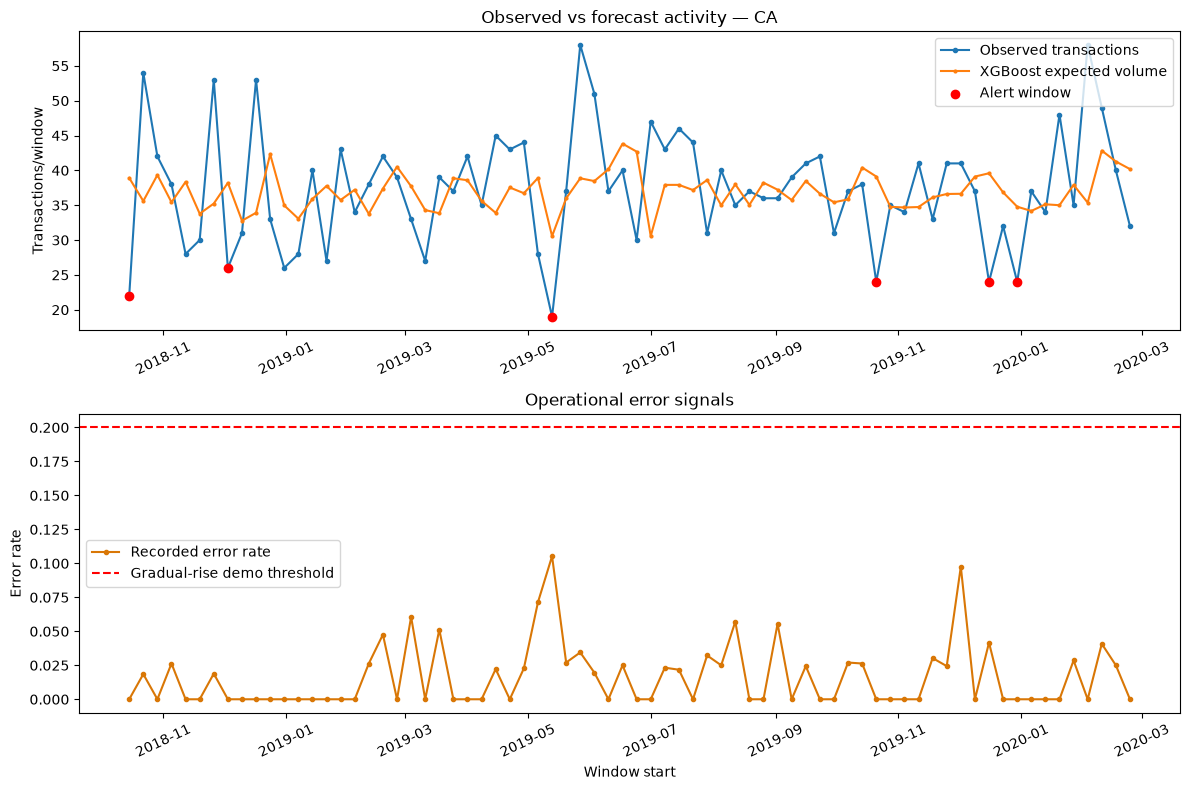

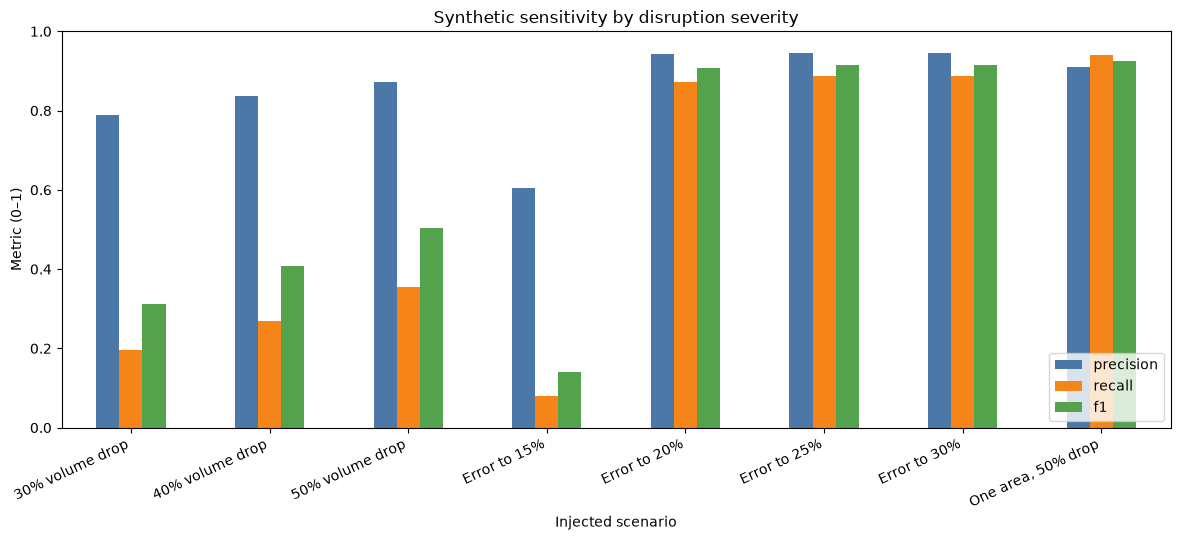

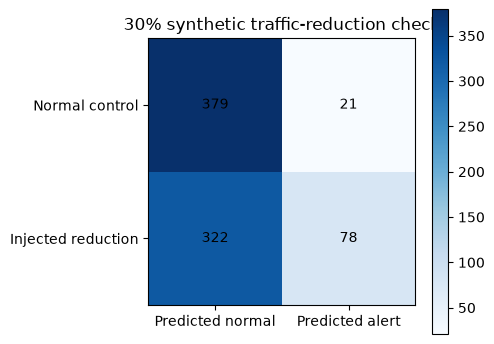

In [11]:
area_for_plot = test['area'].value_counts().index[0]
plot_area = scored_test[scored_test['area'] == area_for_plot].sort_values('window_start').tail(72)
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
axes[0].plot(plot_area['window_start'], plot_area['event_count'], label='Observed transactions', marker='o', ms=3)
axes[0].plot(plot_area['window_start'], plot_area['forecast'], label='XGBoost expected volume', marker='.', ms=4)
alerts = plot_area[plot_area['alert']]
axes[0].scatter(alerts['window_start'], alerts['event_count'], color='red', label='Alert window', zorder=4)
axes[0].set(title=f'Observed vs forecast activity — {area_for_plot}', ylabel='Transactions/window')
axes[0].legend(); axes[0].tick_params(axis='x', rotation=25)
axes[1].plot(plot_area['window_start'], plot_area['error_rate'], color='#d97706', marker='.', label='Recorded error rate')
axes[1].axhline(.20, color='red', ls='--', label='Gradual-rise demo threshold')
axes[1].set(xlabel='Window start', ylabel='Error rate', title='Operational error signals')
axes[1].legend(); axes[1].tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

plot_metrics = benchmark_df.set_index('scenario')[['precision', 'recall', 'f1']]
short_labels = {
    '30% traffic reduction': '30% volume drop', '40% traffic reduction': '40% volume drop', '50% traffic reduction': '50% volume drop',
    'Error rise to 15% (+5 points)': 'Error to 15%', 'Error rise to 20% (+5 points)': 'Error to 20%',
    'Error rise to 25% (+5 points)': 'Error to 25%', 'Error rise to 30% (+5 points)': 'Error to 30%',
    'Single-area 50% reduction proxy': 'One area, 50% drop',
}
ax = plot_metrics.rename(index=short_labels).plot.bar(figsize=(12, 5.5), ylim=(0, 1), color=['#4c78a8', '#f58518', '#54a24b'])
ax.set(title='Synthetic sensitivity by disruption severity', ylabel='Metric (0–1)', xlabel='Injected scenario')
ax.tick_params(axis='x', rotation=25)
for label in ax.get_xticklabels(): label.set_horizontalalignment('right')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

cm_y, cm_pred = benchmark_predictions['30% traffic reduction']
cm = confusion_matrix(cm_y, cm_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4)); im = ax.imshow(cm, cmap='Blues')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['Predicted normal', 'Predicted alert'], yticklabels=['Normal control', 'Injected reduction'], title='30% synthetic traffic-reduction check')
for (i, j), value in np.ndenumerate(cm): ax.text(j, i, str(value), ha='center', va='center')
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()


## 10. Streaming-style scoring replay

Feed chronological held-out area windows to the scorer one record at a time, with a short visible interval. When the local container API is reachable, the notebook sends each record to it; otherwise it uses a matching inline scorer. This is a paced replay of historical windows—not live transaction ingestion, live model latency, or a production stream. If automatic sparsity fallback selected state/day or state/week, the replay cadence is only illustrative.


In [12]:
import urllib.request
from urllib.error import URLError, HTTPError

REPLAY_LIMIT = 30
DELAY_SECONDS = 0.10
API_BASE = os.environ.get('PAYMENT_PULSE_API_URL', 'http://127.0.0.1:8081').rstrip('/')

def score_payload_local(payload):
    observed = float(payload['observed_volume'])
    expected = float(payload['expected_volume'])
    current_error = float(payload['error_rate'])
    previous_error = float(payload.get('previous_error_rate', 0.0))
    traffic_drop = expected >= 3 and observed <= 0.70 * expected
    error_rise = observed >= 3 and current_error >= 0.20 and current_error - previous_error >= 0.05
    watch = (expected >= 3 and observed <= 0.80 * expected) or current_error >= 0.15
    if traffic_drop or error_rise:
        status, action = 'EARLY WARNING', 'Check processor, terminal, and network health; operator decides escalation.'
    elif watch:
        status, action = 'WATCH', 'Compare with independent service telemetry.'
    else:
        status, action = 'NORMAL', 'Continue routine monitoring.'
    return {'area': payload['area'], 'status': status, 'alert': status != 'NORMAL', 'action': action}

api_ready = False
try:
    with urllib.request.urlopen(API_BASE + '/health', timeout=1.5) as response:
        api_ready = response.status == 200
except (URLError, TimeoutError, OSError):
    pass
print('Scoring target:', API_BASE if api_ready else 'inline fallback (container API not reachable)')

replay_rows = scored_test.sort_values('window_start').head(REPLAY_LIMIT)
replay_outputs = []
for i, (_, row) in enumerate(replay_rows.iterrows(), start=1):
    payload = {
        'area': str(row['area']),
        'observed_volume': int(row['event_count']),
        'expected_volume': float(row['forecast']),
        'error_rate': float(row['error_rate']),
        'previous_error_rate': float(row['lag_error_rate']),
    }
    result = score_payload_local(payload)
    if api_ready:
        request = urllib.request.Request(API_BASE + '/score', data=json.dumps(payload).encode('utf-8'), headers={'Content-Type': 'application/json'}, method='POST')
        try:
            with urllib.request.urlopen(request, timeout=2) as response:
                result = json.loads(response.read().decode('utf-8'))
        except (HTTPError, URLError, TimeoutError, OSError, json.JSONDecodeError):
            result = score_payload_local(payload)
            api_ready = False
            print('Container API stopped responding; continuing with inline scorer.')
    replay_outputs.append(result)
    print(f"[{i:02d}] {row['window_start']} | {row['area']} | observed={payload['observed_volume']} expected={payload['expected_volume']:.1f} errors={payload['error_rate']:.1%} | {result['status']} | {result['action']}")
    time.sleep(DELAY_SECONDS)

print('\nRUN SUMMARY')
print(f'Historical windows replayed: {len(replay_outputs)}')
print(f'Early warnings: {sum(r["status"] == "EARLY WARNING" for r in replay_outputs)}')
print(f'Watch alerts: {sum(r["status"] == "WATCH" for r in replay_outputs)}')
print(f'Holdout forecast MAE: {volume_mae:.3f} transactions/window')
print('Synthetic stress-test metrics are listed in the table above; they are not real outage scores.')
print('Outcome: signals support operator checks; they do not confirm outages or trigger payment actions.')


Scoring target: http://127.0.0.1:8081
[01] 2017-01-09 00:00:00 | WI | observed=4 expected=5.5 errors=0.0% | WATCH | Compare this signal with independent service telemetry.
[02] 2017-01-09 00:00:00 | LA | observed=15 expected=16.4 errors=6.7% | NORMAL | Continue routine monitoring.


[03] 2017-01-09 00:00:00 | AZ | observed=2 expected=3.6 errors=0.0% | EARLY WARNING | Check payment processor, terminal, and network health; an operator decides whether to escalate.
[04] 2017-01-09 00:00:00 | OK | observed=11 expected=12.8 errors=0.0% | NORMAL | Continue routine monitoring.


[05] 2017-01-09 00:00:00 | IA | observed=8 expected=9.1 errors=0.0% | NORMAL | Continue routine monitoring.
[06] 2017-01-09 00:00:00 | CT | observed=3 expected=4.2 errors=0.0% | WATCH | Compare this signal with independent service telemetry.


[07] 2017-01-09 00:00:00 | CO | observed=3 expected=4.5 errors=0.0% | EARLY WARNING | Check payment processor, terminal, and network health; an operator decides whether to escalate.
[08] 2017-01-09 00:00:00 | CA | observed=34 expected=42.9 errors=0.0% | WATCH | Compare this signal with independent service telemetry.


[09] 2017-01-09 00:00:00 | NM | observed=1 expected=2.2 errors=0.0% | NORMAL | Continue routine monitoring.
[10] 2017-01-09 00:00:00 | PA | observed=11 expected=14.1 errors=9.1% | WATCH | Compare this signal with independent service telemetry.


...

[23] 2017-01-16 00:00:00 | AZ | observed=3 expected=3.1 errors=0.0% | NORMAL | Continue routine monitoring.
[24] 2017-01-16 00:00:00 | NJ | observed=4 expected=4.1 errors=25.0% | EARLY WARNING | Check payment processor, terminal, and network health; an operator decides whether to escalate.


[25] 2017-01-16 00:00:00 | TX | observed=20 expected=16.6 errors=0.0% | NORMAL | Continue routine monitoring.
[26] 2017-01-16 00:00:00 | WI | observed=3 expected=5.2 errors=0.0% | EARLY WARNING | Check payment processor, terminal, and network health; an operator decides whether to escalate.


[27] 2017-01-16 00:00:00 | CA | observed=30 expected=38.3 errors=0.0% | WATCH | Compare this signal with independent service telemetry.
[28] 2017-01-16 00:00:00 | OK | observed=9 expected=13.4 errors=11.1% | EARLY WARNING | Check payment processor, terminal, and network health; an operator decides whether to escalate.


[29] 2017-01-16 00:00:00 | IA | observed=9 expected=8.6 errors=0.0% | NORMAL | Continue routine monitoring.
[30] 2017-01-16 00:00:00 | MI | observed=8 expected=5.5 errors=0.0% | NORMAL | Continue routine monitoring.



RUN SUMMARY
Historical windows replayed: 30
Early warnings: 8
Watch alerts: 5
Holdout forecast MAE: 3.606 transactions/window
Synthetic stress-test metrics are listed in the table above; they are not real outage scores.
Outcome: signals support operator checks; they do not confirm outages or trigger payment actions.


## 11. Optional Granite operator summary (watsonx.ai)

Granite is disabled by default so **Run All** can complete without interactive credential prompts. Set `RUN_GRANITE = True` in the next cell and rerun it only when you have valid IBM Cloud credentials and project access. API key and project ID are requested through masked prompts. The cell sends aggregate metrics only, prints generated text only, and clears credential variables. The model identifier `ibm/granite-4-h-small` is used in IBM's current SDK examples; availability still depends on your region and plan.


### Granite setup

Create an IBM Cloud API key at **Manage → Access (IAM) → API keys**. In your watsonx.ai project, open **Developer access** and copy the project ID and base URL/region. Use the region code from that page (for example, `us-south` for Dallas), and make sure watsonx.ai is enabled for your account and the model is available in that region. The API key is not your SSH `mykey.pem` file. Keep `RUN_GRANITE = False` for normal Run All; set it to `True` only when you are ready to enter valid credentials in the prompts. Enter the actual API key, not dots or placeholder text. The key is masked; the project ID is an identifier, not a password.


In [13]:
import getpass
import requests

# Set True only when you want to call watsonx.ai; default False keeps Run All non-interactive.
RUN_GRANITE = False
if not RUN_GRANITE:
    print('Granite skipped: set RUN_GRANITE = True and rerun this cell when credentials and project access are available.')
else:
    api_key = getpass.getpass('IBM Cloud API key (masked): ').strip()
    project_id = getpass.getpass('watsonx.ai project ID (masked): ').strip()
    region = input('watsonx.ai region [us-south]: ').strip() or 'us-south'
    token = None
    if not api_key or not project_id:
        print('Granite skipped: credentials were not supplied.')
    else:
        safe_summary = {
            'sample_rows': int(len(raw)),
            'rows_scanned': int(source_rows_scanned),
            'aggregate_windows': int(len(windows)),
            'aggregation_grain': AGGREGATION_GRAIN,
            'holdout_volume_mae': round(float(volume_mae), 3),
            'synthetic_scenarios': benchmark_df[['scenario', 'precision', 'recall', 'f1']].round(3).to_dict(orient='records'),
            'holdout_alerts': int(scored_test.alert.sum()),
        }
        try:
            token_response = requests.post(
                'https://iam.cloud.ibm.com/identity/token',
                data={'grant_type': 'urn:ibm:params:oauth:grant-type:apikey', 'apikey': api_key},
                headers={'Content-Type': 'application/x-www-form-urlencoded'}, timeout=30)
            if not token_response.ok:
                print(f'IBM IAM token request failed (HTTP {token_response.status_code}). Check that this is a valid IBM Cloud API key, not the SSH .pem key.')
            else:
                token = token_response.json().get('access_token')
                if not token:
                    print('IBM IAM returned no access token. Check the IBM Cloud API key and IAM account access.')
                else:
                    chat_response = requests.post(
                        f'https://{region}.ml.cloud.ibm.com/ml/v1/text/chat?version=2024-03-14',
                        headers={'Authorization': 'Bearer ' + token, 'Content-Type': 'application/json', 'Accept': 'application/json'},
                        json={
                            'model_id': 'ibm/granite-4-h-small',
                            'project_id': project_id,
                            'messages': [{'role': 'user', 'content': 'Write three concise operator-facing bullets interpreting these aggregate payment-service monitoring results. Do not claim a confirmed outage. State that all precision, recall, and F1 figures are from injected synthetic scenarios only. Recommend independent checks. Data: ' + json.dumps(safe_summary)}],
                            'max_tokens': 300,
                            'temperature': 0.2,
                        }, timeout=60)
                    if not chat_response.ok:
                        print(f'watsonx.ai inference failed (HTTP {chat_response.status_code}). Check the project ID, matching region, model access, and service entitlement. The API key and project ID were not printed.')
                    else:
                        granite_text = chat_response.json()['choices'][0]['message']['content']
                        print(granite_text)
        except requests.Timeout:
            print('Granite request timed out. Check the network and try again; no secret was printed.')
        except requests.RequestException as exc:
            print(f'Granite network request failed ({type(exc).__name__}). Check connectivity; no secret was printed.')
        except (KeyError, ValueError, TypeError):
            print('Granite returned an unexpected response format. Check model availability and project access; no response payload or secret was printed.')
        finally:
            api_key = None
            project_id = None
            token = None


Granite skipped: set RUN_GRANITE = True and rerun this cell when credentials and project access are available.


## 12. Container deployment and security

- `service/app.py` exposes `/health` and `/score` using only Python's standard library. It consumes aggregate volume/error features produced by the notebook and returns an operator cue; the API scorer is a small threshold-based demo, while XGBoost and Isolation Forest run in this notebook.
- Build and run `service/Dockerfile` on the L1CC VM with a non-root UID, read-only container filesystem, all Linux capabilities dropped, no-new-privileges, memory/CPU/PID limits, and a loopback-only port. Use the commands in the README. This is separate from the prebuilt JupyterLab container.
- Keep the service bound to `127.0.0.1` on the VM and access it through an SSH tunnel. Do not expose port 8081 publicly. Do not mount the CSV, notebook, SSH key, IBM API key, or project ID into the scoring container.
- Keep `.pem`, `.key`, CSV data, API keys, access tokens, and project IDs out of Git and notebook outputs. The Granite cell uses masked runtime prompts and displays only generated text.
- The L1CC VM's security posture and Telum acceleration must be evidenced from the actual VM; this source tree alone does not claim Telum acceleration. Capture Docker build/run output, a successful `/health`/`/score` response, `docker inspect` security settings, and a short live workload recording for the datathon demo.
- This prototype is human decision support. It does not confirm outages or automatically block, reroute, or decline transactions.


## Final results and submission checklist

This notebook reports full-file scan size, uniformly sampled row count, data-quality statistics, event-count distribution, selected area/time grain, chronological XGBoost MAE, Isolation Forest threshold, and synthetic severity-by-severity precision/recall/F1 with graphs. A paced replay sends one held-out historical window at a time to the L1CC container scorer when available. The CSV has no verified outage labels or terminal IDs; if it falls back to state/day or state/week, its time resolution is too coarse for genuine real-time claims. The synthetic input is included beside the notebook; the optional container replay uses the inline scorer if the endpoint is unavailable. Run Granite separately only with valid credentials; the default Run All skips it.
